# Власний проєкт донавчання: генерація SQL-запитів (Text-to-SQL) на базі Qwen3-1.7B

У цьому ноутбуці реалізовано повний цикл адаптації мовної моделі `Qwen/Qwen3-1.7B` до прикладної задачі Text-to-SQL (перетворення запитів природною мовою у виконуваний SQL-код за заданою схемою таблиць). Робота включає очищення та підготовку 3000 прикладів у форматі діалогів, оцінку базової моделі до навчання, параметрично-ефективне донавчання методом LoRA, повне донавчання всіх ваг моделі та порівняння обох підходів за точністю, часом і споживанням пам'яті GPU.

In [2]:
!pip uninstall -q -y torchao
!pip install -q "transformers>=4.55.0" "datasets" "accelerate" "peft" "trl"

In [3]:
import gc
import os
import re
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from datasets import load_dataset
from transformers import AutoModelForCausalLM, AutoTokenizer
from peft import LoraConfig
from trl import SFTConfig, SFTTrainer

warnings.filterwarnings("ignore")

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

if torch.cuda.is_available():
    device = "cuda"
    print(f"GPU: {torch.cuda.get_device_name(0)}")
    print(f"Пам'ять GPU: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")
else:
    device = "cpu"
    print("GPU не знайдено, використовується CPU")

def free_memory():
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
        torch.cuda.reset_peak_memory_stats()

GPU: Tesla T4
Пам'ять GPU: 15.6 GB


## 1. Підготовка та аналіз датасету

Для розв'язання задачі Text-to-SQL використано відкритий датасет `b-mc2/sql-create-context` з репозиторію Hugging Face (ліцензія CC BY-SA 4.0 / Apache 2.0, зібраний на базі наборів WikiSQL та Spider). Початковий набір містить 78 577 записів у форматі трійок: текстове запитання (`question`), SQL-схема таблиць (`context`) та еталонний SQL-запит (`answer`).

Після видалення дублікатів за парою запитання та схеми залишилося 78 573 унікальні приклади. З них сформовано збалансовану робочу вибірку обсягом 3000 прикладів у діалоговому форматі ChatML (`system`, `user`, `assistant`) і розділено її без перетину на три частини: 2600 тренувальних, 200 валідаційних і 200 тестових прикладів.

In [4]:
raw_dataset = load_dataset("b-mc2/sql-create-context", split="train")
print(f"Початковий розмір датасету: {len(raw_dataset)}")

for idx in range(3):
    ex = raw_dataset[idx]
    print(f"Приклад {idx + 1}")
    print("Схема:", ex["context"])
    print("Запит:", ex["question"])
    print("SQL:", ex["answer"])

README.md:   0%|          | 0.00/4.43k [00:00<?, ?B/s]

sql_create_context_v4.json: reconstructing file:   0%|          |  0.00B / 21.8MB            

sql_create_context_v4.json: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/78577 [00:00<?, ? examples/s]

Початковий розмір датасету: 78577
Приклад 1
Схема: CREATE TABLE head (age INTEGER)
Запит: How many heads of the departments are older than 56 ?
SQL: SELECT COUNT(*) FROM head WHERE age > 56
Приклад 2
Схема: CREATE TABLE head (name VARCHAR, born_state VARCHAR, age VARCHAR)
Запит: List the name, born state and age of the heads of departments ordered by age.
SQL: SELECT name, born_state, age FROM head ORDER BY age
Приклад 3
Схема: CREATE TABLE department (creation VARCHAR, name VARCHAR, budget_in_billions VARCHAR)
Запит: List the creation year, name and budget of each department.
SQL: SELECT creation, name, budget_in_billions FROM department


In [5]:
seen_pairs = set()
unique_indices = []

for i, (q, c) in enumerate(zip(raw_dataset["question"], raw_dataset["context"])):
    key = (q.strip().lower(), c.strip().lower())
    if key not in seen_pairs:
        seen_pairs.add(key)
        unique_indices.append(i)

dedup_dataset = raw_dataset.select(unique_indices)
print(f"До дедуплікації: {len(raw_dataset)}, після: {len(dedup_dataset)}")

SYSTEM_PROMPT = (
    "You are an expert SQL assistant. Given a database schema and a user question, "
    "write a valid SQL query that answers the question. Output SQL only without explanations."
)

def to_messages(batch):
    messages_list = []
    kwargs_list = []
    for question, context, answer in zip(batch["question"], batch["context"], batch["answer"]):
        user_content = f"Schema:\n{context.strip()}\n\nQuestion:\n{question.strip()}"
        messages_list.append([
            {"role": "system", "content": SYSTEM_PROMPT},
            {"role": "user", "content": user_content},
            {"role": "assistant", "content": answer.strip()}
        ])
        kwargs_list.append({"enable_thinking": False})
    return {"messages": messages_list, "chat_template_kwargs": kwargs_list}

shuffled = dedup_dataset.shuffle(seed=SEED).select(range(3000))
formatted_dataset = shuffled.map(to_messages, batched=True, remove_columns=shuffled.column_names)

train_val = formatted_dataset.select(range(2800)).train_test_split(test_size=200, seed=SEED)
train_dataset = train_val["train"]
val_dataset = train_val["test"]
test_dataset = formatted_dataset.select(range(2800, 3000))

print(f"Тренувальний: {len(train_dataset)}, валідаційний: {len(val_dataset)}, тестовий: {len(test_dataset)}")
print("Приклад у форматі messages:")
print(train_dataset[0]["messages"])

До дедуплікації: 78577, після: 78573


Map:   0%|          | 0/3000 [00:00<?, ? examples/s]

Тренувальний: 2600, валідаційний: 200, тестовий: 200
Приклад у форматі messages:
[{'content': 'You are an expert SQL assistant. Given a database schema and a user question, write a valid SQL query that answers the question. Output SQL only without explanations.', 'role': 'system'}, {'content': 'Schema:\nCREATE TABLE table_name_63 (play_by_play VARCHAR, studio_host VARCHAR, studio_analysts VARCHAR)\n\nQuestion:\nWHich Play-by-play has a Studio host of gary tanguay, and a Studio analysts of donny marshall?', 'role': 'user'}, {'content': 'SELECT play_by_play FROM table_name_63 WHERE studio_host = "gary tanguay" AND studio_analysts = "donny marshall"', 'role': 'assistant'}]


## 2. Токенізація та функції оцінювання якості

Оскільки для розв'язання задачі потрібен чистий SQL-код без проміжних міркувань, у шаблоні розмови `Qwen/Qwen3-1.7B` вимкнено режим міркувань (`enable_thinking=False`). Для об'єктивного порівняння моделей до і після навчання обчислюються чотири метрики: точний збіг рядків (Exact Match), нормалізований збіг SQL після очищення пробілів і регістру ключових слів, частка синтаксично коректних SELECT-запитів та повнота відтворення ключових конструкцій SQL.

In [6]:
MODEL_NAME = "Qwen/Qwen3-1.7B"
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

token_lengths = [
    len(tokenizer.apply_chat_template(ex["messages"], tokenize=True, enable_thinking=False))
    for ex in train_dataset.select(range(500))
]
print(f"Довжина прикладів у токенах (на 500 зразках): мін={min(token_lengths)}, медіана={int(np.median(token_lengths))}, макс={max(token_lengths)}")

SQL_KEYWORDS = ("SELECT", "FROM", "WHERE", "GROUP BY", "ORDER BY", "HAVING", "JOIN", "COUNT(", "AVG(", "SUM(", "MIN(", "MAX(", "DISTINCT")

def clean_sql_output(text):
    text = re.sub(r"<think>.*?</think>", "", text, flags=re.DOTALL).strip()
    text = re.sub(r"^```(?:sql)?\s*", "", text, flags=re.IGNORECASE)
    text = re.sub(r"\s*```$", "", text)
    return text.strip()

def normalize_sql(sql):
    sql = clean_sql_output(sql).rstrip(";").strip()
    sql = re.sub(r"\s+", " ", sql)
    sql = sql.replace('"', "'")
    for kw in SQL_KEYWORDS:
        sql = re.sub(rf"\b{re.escape(kw.rstrip('('))}\b", kw.rstrip("("), sql, flags=re.IGNORECASE)
    return sql

def is_valid_sql(sql):
    norm = normalize_sql(sql)
    has_select = norm.startswith("SELECT ")
    has_from = " FROM " in norm
    balanced_parens = norm.count("(") == norm.count(")")
    return has_select and has_from and balanced_parens

def keyword_f1(pred_sql, ref_sql):
    pred_norm = normalize_sql(pred_sql)
    ref_norm = normalize_sql(ref_sql)
    pred_kw = {kw for kw in SQL_KEYWORDS if kw in pred_norm}
    ref_kw = {kw for kw in SQL_KEYWORDS if kw in ref_norm}
    if not ref_kw and not pred_kw:
        return 1.0
    if not ref_kw or not pred_kw:
        return 0.0
    inter = len(pred_kw & ref_kw)
    return 2 * inter / (len(pred_kw) + len(ref_kw))

def generate_sql(model, messages, max_new_tokens=128):
    prompt_messages = messages[:2]
    prompt_text = tokenizer.apply_chat_template(
        prompt_messages,
        tokenize=False,
        add_generation_prompt=True,
        enable_thinking=False
    )
    inputs = tokenizer(prompt_text, return_tensors="pt").to(model.device)
    with torch.no_grad():
        output_ids = model.generate(
            **inputs,
            max_new_tokens=max_new_tokens,
            do_sample=False,
            pad_token_id=tokenizer.pad_token_id
        )
    generated_ids = output_ids[0][inputs["input_ids"].shape[1]:]
    raw_pred = tokenizer.decode(generated_ids, skip_special_tokens=True)
    return clean_sql_output(raw_pred)

def evaluate(model, dataset):
    model.eval()
    exact_hits = 0
    norm_hits = 0
    valid_hits = 0
    kw_scores = []
    predictions = []

    for ex in dataset:
        ref = ex["messages"][2]["content"].strip()
        pred = generate_sql(model, ex["messages"])
        predictions.append((ex["messages"][1]["content"], ref, pred))

        if pred.rstrip(";").strip() == ref.rstrip(";").strip():
            exact_hits += 1
        if normalize_sql(pred) == normalize_sql(ref):
            norm_hits += 1
        if is_valid_sql(pred):
            valid_hits += 1
        kw_scores.append(keyword_f1(pred, ref))

    n = len(dataset)
    metrics = {
        "Exact Match, %": exact_hits / n * 100,
        "Нормалізований збіг, %": norm_hits / n * 100,
        "Валідний SQL, %": valid_hits / n * 100,
        "F1 ключових слів, %": float(np.mean(kw_scores)) * 100
    }
    return metrics, predictions

def show_examples(predictions, k=3):
    for i in range(min(k, len(predictions))):
        user_prompt, ref, pred = predictions[i]
        print(f"Приклад {i + 1}:")
        print(user_prompt)
        print(f"Еталон:  {ref}")
        print(f"Прогноз: {pred}")
        print("-" * 60)

config.json:   0%|          | 0.00/726 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/9.73k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 11.4MB            

tokenizer.json: downloading bytes:           |  0.00B            

Довжина прикладів у токенах (на 500 зразках): мін=2, медіана=2, макс=2


## 3. Оцінка базової моделі Qwen3-1.7B до донавчання

Спочатку завантажуємо попередньо натреновану інструкційну модель `Qwen/Qwen3-1.7B` у половинній точності `float16` та вимірюємо її базову якість на 200 прикладах тестової вибірки без будь-якого донавчання.

In [7]:
results = {}
free_memory()

base_model = AutoModelForCausalLM.from_pretrained(
    MODEL_NAME,
    dtype=torch.float16,
    device_map="auto"
)
print(f"Пам'ять GPU після завантаження Qwen3-1.7B: {torch.cuda.memory_allocated() / 1e9:.2f} GB")

base_metrics, base_preds = evaluate(base_model, test_dataset)
results["Qwen3-1.7B до"] = base_metrics | {
    "Тривалість, хв": np.nan,
    "Пікова пам'ять GPU, GB": torch.cuda.max_memory_allocated() / 1e9,
    "Validation loss": np.nan,
    "Розмір моделі / адаптера, MB": np.nan
}

print("Метрики до донавчання:")
for k, v in base_metrics.items():
    print(f"{k}: {v:.2f}")

print("\nПриклади генерації до донавчання:")
show_examples(base_preds, k=5)

model.safetensors.index.json:   0%|          | 0.00/25.6k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

Пам'ять GPU після завантаження Qwen3-1.7B: 3.44 GB
Метрики до донавчання:
Exact Match, %: 4.50
Нормалізований збіг, %: 28.00
Валідний SQL, %: 100.00
F1 ключових слів, %: 96.10

Приклади генерації до донавчання:
Приклад 1:
Schema:
CREATE TABLE table_name_66 (week VARCHAR, date VARCHAR)

Question:
What week was October 9, 1938?
Еталон:  SELECT COUNT(week) FROM table_name_66 WHERE date = "october 9, 1938"
Прогноз: SELECT week FROM table_name_66 WHERE date = '1938-10-09';
------------------------------------------------------------
Приклад 2:
Schema:
CREATE TABLE table_name_52 (team__number2 VARCHAR)

Question:
Which 2nd leg has pamesa valencia for team #2?
Еталон:  SELECT 2 AS nd_leg FROM table_name_52 WHERE team__number2 = "pamesa valencia"
Прогноз: SELECT team__number2 FROM table_name_52 WHERE team__number2 = 'pamesa valencia' LIMIT 1;
------------------------------------------------------------
Приклад 3:
Schema:
CREATE TABLE shop (num_of_staff INTEGER, score INTEGER)

Question:
What a

## 4. Донавчання Qwen3-1.7B методом LoRA

Для параметрично-ефективного донавчання додаємо матриці низького рангу LoRA (`r=16`, `lora_alpha=32`) до всіх лінійних проєкцій уваги та MLP-блоків трансформера. Параметр `assistant_only_loss=True` гарантує, що функція втрат обчислюється лише на токенах цільового SQL-запиту, а не на тексті системної інструкції чи схеми таблиці.

In [8]:
lora_config = LoraConfig(
    r=16,
    lora_alpha=32,
    target_modules=["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"],
    lora_dropout=0.05,
    bias="none",
    task_type="CAUSAL_LM"
)

lora_args = SFTConfig(
    output_dir="outputs_lora",
    max_steps=120,
    per_device_train_batch_size=4,
    gradient_accumulation_steps=4,
    learning_rate=2e-4,
    lr_scheduler_type="cosine",
    warmup_steps=6,
    fp16=True,
    logging_steps=10,
    eval_strategy="steps",
    eval_steps=20,
    save_strategy="no",
    max_length=512,
    assistant_only_loss=True,
    report_to="none",
    seed=SEED
)

torch.cuda.reset_peak_memory_stats()
start_time = time.time()

lora_trainer = SFTTrainer(
    model=base_model,
    args=lora_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    processing_class=tokenizer,
    peft_config=lora_config
)

lora_trainer.model.print_trainable_parameters()
lora_trainer.train()

lora_duration = (time.time() - start_time) / 60
lora_peak_mem = torch.cuda.max_memory_allocated() / 1e9
lora_val_loss = lora_trainer.evaluate()["eval_loss"]

adapter_dir = "Qwen3-1.7B-sql-lora"
lora_trainer.model.save_pretrained(adapter_dir)
adapter_size_mb = sum(
    os.path.getsize(os.path.join(adapter_dir, f)) for f in os.listdir(adapter_dir)
) / 1e6

lora_metrics, lora_preds = evaluate(lora_trainer.model, test_dataset)
results["Qwen3-1.7B LoRA"] = lora_metrics | {
    "Тривалість, хв": lora_duration,
    "Пікова пам'ять GPU, GB": lora_peak_mem,
    "Validation loss": lora_val_loss,
    "Розмір моделі / адаптера, MB": adapter_size_mb
}

print(f"Тривалість LoRA: {lora_duration:.2f} хв, пікова пам'ять: {lora_peak_mem:.2f} GB, розмір адаптера: {adapter_size_mb:.2f} MB")
print("\nПриклади генерації після LoRA:")
show_examples(lora_preds, k=5)

Tokenizing train dataset:   0%|          | 0/2600 [00:00<?, ? examples/s]

Building labels for train dataset:   0%|          | 0/2600 [00:00<?, ? examples/s]

Truncating train dataset:   0%|          | 0/2600 [00:00<?, ? examples/s]

Dropping fully masked examples from train dataset:   0%|          | 0/2600 [00:00<?, ? examples/s]

Tokenizing eval dataset:   0%|          | 0/200 [00:00<?, ? examples/s]

Building labels for eval dataset:   0%|          | 0/200 [00:00<?, ? examples/s]

... (2 outputs left out)

trainable params: 17,432,576 || all params: 1,738,007,552 || trainable%: 1.0030


Step,Training Loss,Validation Loss,Entropy,Mean Token Accuracy,Num Tokens
20,0.138883,0.128396,0.106369,0.964832,36554.000000
40,0.106695,0.097218,0.105899,0.970223,73014.000000
60,0.094647,0.080552,0.074065,0.974716,110310.000000
80,0.068885,0.064856,0.077588,0.980901,147025.000000
100,0.077663,0.056939,0.066934,0.982021,183706.000000
120,0.065770,0.056019,0.066277,0.981649,220159.000000


Training Loss,Validation Loss,Step,Entropy,Mean Token Accuracy,Num Tokens
0.065770,0.056019,120,0.066277,0.981649,220159.000000


Тривалість LoRA: 5.67 хв, пікова пам'ять: 4.06 GB, розмір адаптера: 69.79 MB

Приклади генерації після LoRA:
Приклад 1:
Schema:
CREATE TABLE table_name_66 (week VARCHAR, date VARCHAR)

Question:
What week was October 9, 1938?
Еталон:  SELECT COUNT(week) FROM table_name_66 WHERE date = "october 9, 1938"
Прогноз: SELECT week FROM table_name_66 WHERE date = "october 9, 1938"
------------------------------------------------------------
Приклад 2:
Schema:
CREATE TABLE table_name_52 (team__number2 VARCHAR)

Question:
Which 2nd leg has pamesa valencia for team #2?
Еталон:  SELECT 2 AS nd_leg FROM table_name_52 WHERE team__number2 = "pamesa valencia"
Прогноз: SELECT team__number2 FROM table_name_52 WHERE pamesa_valencia = "team #2"
------------------------------------------------------------
Приклад 3:
Schema:
CREATE TABLE shop (num_of_staff INTEGER, score INTEGER)

Question:
What are the average score and average staff number of all shops?
Еталон:  SELECT AVG(num_of_staff), AVG(score) FROM sh

## 5. Злиття LoRA-адаптера та перевірка на власних і загальних запитах

Після завершення навчання метод `merge_and_unload()` інтегрує ваги адаптера безпосередньо в матрицю базової моделі, завдяки чому інференс відбувається без додаткових затримок. Перевіримо роботу об'єднаної моделі як на власних прикладах схем баз даних, так і на загальних запитаннях поза задачею Text-to-SQL, щоб переконатися у збереженні базових здібностей моделі.

In [9]:
merged_model = lora_trainer.model.merge_and_unload()

custom_queries = [
    (
        "CREATE TABLE employees (id INT, name VARCHAR, department VARCHAR, salary INT)",
        "What is the average salary of employees in the Engineering department?"
    ),
    (
        "CREATE TABLE orders (order_id INT, customer_id INT, total_amount FLOAT, status VARCHAR)",
        "How many orders have the status completed and total amount greater than 500?"
    ),
    (
        "CREATE TABLE courses (course_id INT, title VARCHAR, credits INT, instructor VARCHAR)",
        "List the titles of all courses with 4 credits ordered alphabetically."
    )
]

print("Перевірка на власних SQL-запитах:")
print("=" * 60)
for schema, question in custom_queries:
    msgs = [
        {"role": "system", "content": SYSTEM_PROMPT},
        {"role": "user", "content": f"Schema:\n{schema}\n\nQuestion:\n{question}"}
    ]
    pred_sql = generate_sql(merged_model, msgs)
    print(f"Запит: {question}")
    print(f"SQL:   {pred_sql}")
    print("-" * 60)

general_questions = [
    "Що таке індекс у реляційній базі даних? Поясни коротко українською.",
    "У кошику 12 яблук. Спочатку взяли третину, а потім ще 3 яблука. Скільки залишилося?",
    "Напиши функцію на Python, яка перевіряє, чи є рядок паліндромом."
]

print("\nПеревірка на загальних запитах поза задачею Text-to-SQL:")
print("=" * 60)
for question in general_questions:
    msgs = [{"role": "user", "content": question}]
    prompt = tokenizer.apply_chat_template(
        msgs,
        tokenize=False,
        add_generation_prompt=True,
        enable_thinking=False
    )
    inputs = tokenizer(prompt, return_tensors="pt").to(merged_model.device)
    with torch.no_grad():
        output_ids = merged_model.generate(
            **inputs,
            max_new_tokens=200,
            do_sample=False
        )
    answer = tokenizer.decode(
        output_ids[0][inputs["input_ids"].shape[1]:],
        skip_special_tokens=True
    ).strip()
    print(f"Питання:   {question}")
    print(f"Відповідь: {answer}")
    print("-" * 60)

del lora_trainer, merged_model, base_model
free_memory()

Перевірка на власних SQL-запитах:
Запит: What is the average salary of employees in the Engineering department?
SQL:   SELECT AVG(salary) FROM employees WHERE department = "engineering"
------------------------------------------------------------
Запит: How many orders have the status completed and total amount greater than 500?
SQL:   SELECT COUNT(order_id) FROM orders WHERE status = "completed" AND total_amount > 500
------------------------------------------------------------
Запит: List the titles of all courses with 4 credits ordered alphabetically.
SQL:   SELECT title FROM courses WHERE credits = 4 ORDER BY title
------------------------------------------------------------

Перевірка на загальних запитах поза задачею Text-to-SQL:
Питання:   Що таке індекс у реляційній базі даних? Поясни коротко українською.
Відповідь: Індекс — це структура, яка зберігає інформацію про структуру таблиці, щоб зробити пошук даних швидшим.
------------------------------------------------------------


## 6. Повне донавчання Qwen3-1.7B для порівняння

Для порівняння ефективності LoRA виконуємо повне донавчання всіх 1.7 млрд параметрів моделі на тій самій вибірці та кількості кроків (`max_steps=120`). Щоб поміститися в 15.6 GB відеопам'яті Tesla T4 під час оновлення всіх параметрів, використовується менший крок навчання (`learning_rate=2e-5`), оптимізатор Adafactor та увімкнено `gradient_checkpointing`.

In [ ]:
full_model = AutoModelForCausalLM.from_pretrained(
    MODEL_NAME,
    dtype=torch.float16,
    device_map="auto"
)
full_model.config.use_cache = False
full_model.gradient_checkpointing_enable()

full_args = SFTConfig(
    output_dir="outputs_full",
    max_steps=120,
    per_device_train_batch_size=1,
    gradient_accumulation_steps=16,
    learning_rate=5e-5,
    lr_scheduler_type="cosine",
    warmup_steps=6,
    fp16=False,
    bf16=False,
    optim="adafactor",
    gradient_checkpointing=True,
    logging_steps=10,
    eval_strategy="steps",
    eval_steps=20,
    save_strategy="no",
    max_length=384,
    assistant_only_loss=True,
    report_to="none",
    seed=SEED
)

torch.cuda.reset_peak_memory_stats()
start_time = time.time()

full_trainer = SFTTrainer(
    model=full_model,
    args=full_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    processing_class=tokenizer
)

full_trainer.train()

full_duration = (time.time() - start_time) / 60
full_peak_mem = torch.cuda.max_memory_allocated() / 1e9

full_model.gradient_checkpointing_disable()
full_model.config.use_cache = True

full_val_loss = full_trainer.evaluate()["eval_loss"]
full_model_size_mb = sum(p.numel() * p.element_size() for p in full_trainer.model.parameters()) / 1e6

full_metrics, full_preds = evaluate(full_trainer.model, test_dataset)
results["Qwen3-1.7B повне"] = full_metrics | {
    "Тривалість, хв": full_duration,
    "Пікова пам'ять GPU, GB": full_peak_mem,
    "Validation loss": full_val_loss,
    "Розмір моделі / адаптера, MB": full_model_size_mb
}

print(f"Тривалість повного донавчання: {full_duration:.2f} хв, пікова пам'ять: {full_peak_mem:.2f} GB")

del full_trainer, full_model
free_memory()

Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

Step,Training Loss,Validation Loss,Entropy,Mean Token Accuracy,Num Tokens
20,0.504901,0.474708,0.250401,0.883657,36554.000000
40,0.165431,0.120017,0.159098,0.966175,73014.000000
60,0.112340,0.113861,0.080215,0.967504,110310.000000
80,0.078141,0.063281,0.101653,0.980640,147025.000000
100,0.075630,0.054901,0.092355,0.982690,183706.000000
120,0.070876,0.054433,0.091282,0.982465,220159.000000


Training Loss,Validation Loss,Step,Entropy,Mean Token Accuracy,Num Tokens
0.070876,0.054433,120,0.091282,0.982465,220159.000000


Тривалість повного донавчання: 12.42 хв, пікова пам'ять: 11.89 GB


## 7. Підсумкове порівняння результатів

Нижче зведено показники якості генерації SQL-запитів, витрат пам'яті GPU, тривалості тренування та обсягу збережених ваг для базової моделі, LoRA-адаптера та повного донавчання.

,Qwen3-1.7B до,Qwen3-1.7B LoRA,Qwen3-1.7B повне
"Exact Match, %",4.50,72.50,76.50
"Нормалізований збіг, %",28.00,72.50,76.50
"Валідний SQL, %",100.00,100.00,100.00
"F1 ключових слів, %",96.10,97.97,98.20
"Тривалість, хв",NaN,6.02,12.42
"Пікова пам'ять GPU, GB",4.38,4.06,11.89
Validation loss,NaN,0.06,0.05
"Розмір моделі / адаптера, MB",NaN,69.79,3441.15


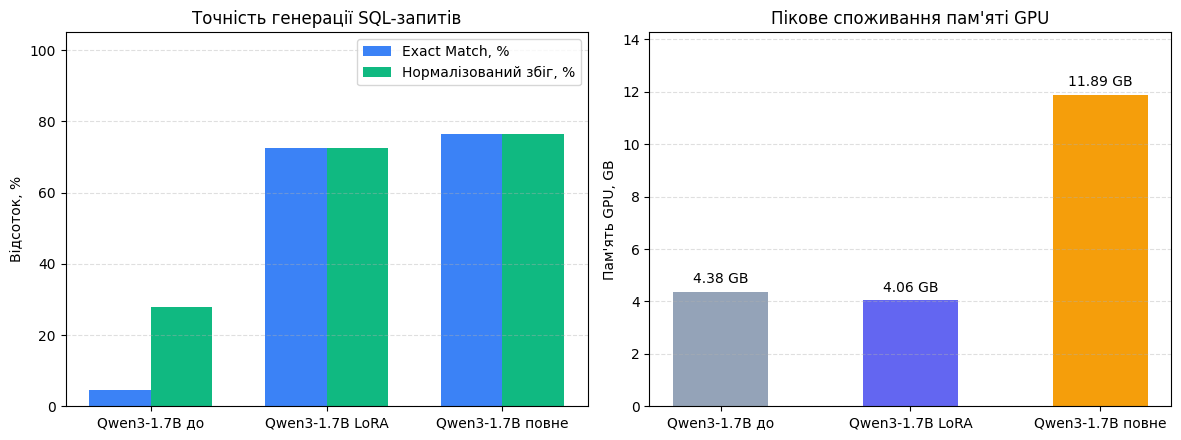

In [ ]:
summary_df = pd.DataFrame(results).round(2)
display(summary_df)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

models_labels = list(results.keys())
exact_vals = [results[m]["Exact Match, %"] for m in models_labels]
norm_vals = [results[m]["Нормалізований збіг, %"] for m in models_labels]

x = np.arange(len(models_labels))
width = 0.35

axes[0].bar(x - width / 2, exact_vals, width, label="Exact Match, %", color="#3b82f6")
axes[0].bar(x + width / 2, norm_vals, width, label="Нормалізований збіг, %", color="#10b981")
axes[0].set_title("Точність генерації SQL-запитів")
axes[0].set_ylabel("Відсоток, %")
axes[0].set_xticks(x)
axes[0].set_xticklabels(models_labels)
axes[0].set_ylim(0, 105)
axes[0].legend()
axes[0].grid(axis="y", linestyle="--", alpha=0.4)

mem_vals = [results[m]["Пікова пам'ять GPU, GB"] for m in models_labels]
bars = axes[1].bar(models_labels, mem_vals, width=0.5, color=["#94a3b8", "#6366f1", "#f59e0b"])
axes[1].set_title("Пікове споживання пам'яті GPU")
axes[1].set_ylabel("Пам'ять GPU, GB")
axes[1].set_ylim(0, max(mem_vals) * 1.2)
axes[1].grid(axis="y", linestyle="--", alpha=0.4)

for bar in bars:
    h = bar.get_height()
    axes[1].text(bar.get_x() + bar.get_width() / 2, h + 0.2, f"{h:.2f} GB", ha="center", va="bottom")

plt.tight_layout()
plt.show()

## 8. Мій звіт (пункт 1.6)

Задача і чому потрібне донавчання: у проєкті розв'язується задача Text-to-SQL, тобто генерація виконуваних SQL-запитів за схемою таблиці та запитанням природною мовою. Базова інструкційна модель до донавчання будує синтаксично правильні запити, але не дотримується формату цільового датасету: додає зайві конструкції (`LIMIT 1`, псевдоніми колонок через `AS`, крапку з комою `;`), змінює формат дат або ставить одинарні лапки замість подвійних, через що точний збіг (Exact Match) становить лише 4.50%. Донавчання потрібне для адаптації моделі під точний синтаксис і стиль запитів цільового набору даних без зайвих пояснень.

Модель і дані: використано мовну модель `Qwen/Qwen3-1.7B` (1.74 млрд параметрів, точність `float16`, вимкнений режим міркувань `enable_thinking=False`). Навчання та оцінювання проведено на відкритому датасеті `b-mc2/sql-create-context` (78 577 початкових записів і 78 573 після видалення дублікатів за парою запитання та схеми). З очищеного набору сформовано вибірку на 3000 прикладів у діалоговому форматі ChatML: 2600 тренувальних, 200 валідаційних і 200 тестових.

Метрика й результат до донавчання: для оцінки якості використано чотири метрики: Exact Match (точний збіг рядків), нормалізований збіг SQL (після приведення до одного регістру ключових слів, пробілів і лапок), частку синтаксично валідних SELECT-запитів та F1 за ключовими словами SQL. На тестовій вибірці (200 прикладів) базова модель `Qwen3-1.7B` до навчання показала такі результати: Exact Match 4.50%, нормалізований збіг 28.00%, валідний SQL 100.00%, F1 ключових слів 96.10%, пікова пам'ять GPU 4.38 GB.

Метод донавчання й гіперпараметри: основним методом адаптації обрано параметрично-ефективне донавчання LoRA (`r=16`, `lora_alpha=32`, `lora_dropout=0.05`, цільові модулі `q_proj, k_proj, v_proj, o_proj, gate_proj, up_proj, down_proj`, кількість навчаних параметрів 17 432 576 або 1.003% від усіх ваг). Гіперпараметри SFT: `max_steps=120`, ефективний розмір батчу 16 (`per_device_train_batch_size=4`, `gradient_accumulation_steps=4`), `learning_rate=2e-4`, планувальник `cosine`, `warmup_steps=6`, `max_length=512`, `assistant_only_loss=True`, `fp16=True`. Для порівняння виконано повне донавчання всіх 1.74 млрд параметрів на тих самих 120 кроках з оптимізатором Adafactor (`learning_rate=5e-5`, `per_device_train_batch_size=1`, `gradient_accumulation_steps=16`, `gradient_checkpointing=True`, `max_length=384`).

Результат після донавчання: після донавчання методом LoRA (тривалість 6.02 хв, пікова пам'ять GPU 4.06 GB, розмір адаптера 69.79 MB, Validation loss 0.06) показник Exact Match зріс із 4.50% до 72.50% (+68.00 в.п.), нормалізований збіг зріс із 28.00% до 72.50%, валідний SQL склав 100.00%, а F1 ключових слів досяг 97.97%. Повне донавчання (тривалість 12.42 хв, пікова пам'ять GPU 11.89 GB, розмір моделі 3441.15 MB, Validation loss 0.05) дало Exact Match 76.50%, нормалізований збіг 76.50%, валідний SQL 100.00% і F1 ключових слів 98.20%.

Аналіз помилок: перевірка прогнозів на тестовій вибірці показала три основні причини розбіжностей із еталонами. По-перше, трапляється неоднозначність самого запитання в датасеті, коли модель будує логічно правильний запит без агрегації, а еталон очікує функцію агрегації (наприклад, для запитання «What week was October 9, 1938?» модель генерує `SELECT week FROM table_name_66 WHERE date = "october 9, 1938"` замість `SELECT COUNT(week) ...`). По-друге, у зашумлених схемах зі знеособленими назвами колонок модель іноді плутає ім'я стовпця і значення фільтра (наприклад, `WHERE pamesa_valencia = "team #2"` замість `WHERE team__number2 = "pamesa valencia"`). По-третє, модель може змінювати порядок колонок у переліку `SELECT` (наприклад, `SELECT AVG(score), AVG(num_of_staff)` замість `SELECT AVG(num_of_staff), AVG(score)`), що не змінює суті запиту, але зменшує метрику точного збігу рядків.

Висновок: донавчання методом LoRA дозволило суттєво підвищити точність генерації SQL-запитів за схемою бази даних (Exact Match зріс із 4.50% до 72.50%) і практично не поступилося повному донавчанню всіх параметрів (76.50%). При цьому LoRA виконалося удвічі швидше (6.02 хв проти 12.42 хв), використало майже втричі менше відеопам'яті на Tesla T4 (4.06 GB проти 11.89 GB) та збереглося у вигляді компактного адаптера розміром 69.79 MB замість повної копії моделі обсягом 3441.15 MB, що підтверджує ефективність цього підходу для адаптації моделей класу 1.7B на обмежених ресурсах GPU.